In [1]:
import pandas as pd

In [2]:
pd.read_csv("problem_08_parking_tickets (1).csv")

,ticket_id,vehicle_type,vehicle_no,slot_id,entry_time,exit_time,duration_min,fee_charged,payment_mode
0,PK500699,Car,TN 52 QH 5330,C13,26-04-2025 19:37,26-04-2025 22:03,146,90,FASTag
1,PK500257,Car,TN 86 XD 9407,A14,13-04-2025 15:59,13-04-2025 18:05,126,90,UPI
2,PK500090,Car,TN 42 OG 4956,C23,19-04-2025 15:24,NaN,33,30,Cash
3,PK500186,Bike,TN 93 BY 7552,A38,22-04-2025 13:08,22-04-2025 16:08,180,30,Cash
4,PK500525,CAR,TN 60 YK 1063,A13,19-04-2025 08:38,19-04-2025 09:25,47,30,UPI
...,...,...,...,...,...,...,...,...,...
716,PK500137,Truck,TN 26 XM 8519,C10,16-04-2025 07:37,16-04-2025 09:09,92,120,Cash
717,PK500134,Bike,TN 42 PP 7142,C09,20-04-2025 20:01,20-04-2025 20:56,55,10,FASTag
718,PK500362,Car,TN 08 JN 4852,A04,22-04-2025 10:38,22-04-2025 11:47,69,60,FASTag
719,PK500341,Bike,TN 84 MU 2251,B15,13-04-2025 22:20,14-04-2025 00:52,152,30,FASTag


In [3]:
import math
from datetime import datetime

parking = {}
capacity = 50

rates = {
    "bike": 10,
    "car": 30,
    "truck": 60
}

def vehicle_entry():
    number = input("Enter vehicle number: ")
    vehicle = input("Enter vehicle type: ").lower()

    if vehicle not in rates:
        print("Invalid vehicle type")
        return

    if len(parking) >= capacity:
        print("Parking is full")
        return

    if number in parking:
        print("Vehicle already parked")
        return

    entry = datetime.now()

    parking[number] = [vehicle, entry]

    print("Vehicle entry recorded successfully")


def vehicle_exit():
    number = input("Enter vehicle number: ")

    if number not in parking:
        print("Vehicle not found")
        return

    vehicle, entry = parking.pop(number)

    exit_time = datetime.now()

    duration = (exit_time - entry).total_seconds() / 3600

    hours = max(1, math.ceil(duration))

    fee = hours * rates[vehicle]

    print("Vehicle:", number)
    print("Duration:", round(duration, 2), "hours")
    print("Parking Fee: Rs.", fee)


def free_slots():
    print("Total Slots:", capacity)
    print("Occupied Slots:", len(parking))
    print("Free Slots:", capacity - len(parking))


while True:
    print("\n1. Vehicle Entry")
    print("2. Vehicle Exit")
    print("3. Show Free Slots")
    print("4. Exit")

    choice = input("Enter choice: ")

    if choice == "1":
        vehicle_entry()
    elif choice == "2":
        vehicle_exit()
    elif choice == "3":
        free_slots()
    elif choice == "4":
        break
    else:
        print("Invalid choice")


1. Vehicle Entry
2. Vehicle Exit
3. Show Free Slots
4. Exit
Enter choice: 1
Enter vehicle number: TN 52 QH 5330
Enter vehicle type: Car
Vehicle entry recorded successfully

1. Vehicle Entry
2. Vehicle Exit
3. Show Free Slots
4. Exit
Enter choice: 3
Total Slots: 50
Occupied Slots: 1
Free Slots: 49

1. Vehicle Entry
2. Vehicle Exit
3. Show Free Slots
4. Exit
Enter choice: 4


In [31]:
import pandas as pd
import numpy as np

# Corrected filename to point to the actual raw dataset in your workspace
df = pd.read_csv("problem_08_parking_tickets (1).csv")

rates = {
    "bike": 10,
    "car": 30,
    "truck": 60
}

df["vehicle_type"] = df["vehicle_type"].str.lower().str.strip()

# Safely convert duration and fee columns to numeric to handle empty/invalid strings
df["duration_min"] = pd.to_numeric(df["duration_min"], errors='coerce')
df["fee_charged"] = pd.to_numeric(df["fee_charged"], errors='coerce')

df["expected_fee"] = (
    np.ceil(df["duration_min"] / 60).clip(lower=1)
    * df["vehicle_type"].map(rates)
)

df["difference"] = df["fee_charged"] - df["expected_fee"]

df["status"] = np.where(
    df["difference"].isna(), "Unknown",
    np.where(df["difference"] > 0, "Overcharged",
             np.where(df["difference"] < 0, "Undercharged", "Correct"))
)

print(df[["vehicle_type", "duration_min",
          "fee_charged", "expected_fee", "status"]])

print("\nFee Verification:")
print(df["status"].value_counts())

print("\nOvercharged Tickets:")
print(df[df["status"] == "Overcharged"])

print("\nUndercharged Tickets:")
print(df[df["status"] == "Undercharged"])

    vehicle_type  duration_min  fee_charged  expected_fee   status
0            car           146         90.0          90.0  Correct
1            car           126         90.0          90.0  Correct
2            car            33         30.0          30.0  Correct
3           bike           180         30.0          30.0  Correct
4            car            47         30.0          30.0  Correct
..           ...           ...          ...           ...      ...
716        truck            92        120.0         120.0  Correct
717         bike            55         10.0          10.0  Correct
718          car            69         60.0          60.0  Correct
719         bike           152         30.0          30.0  Correct
720         bike           114         20.0          20.0  Correct

[721 rows x 5 columns]

Fee Verification:
status
Correct         653
Unknown          61
Undercharged      4
Overcharged       3
Name: count, dtype: int64

Overcharged Tickets:
    ticket_id vehi

In [32]:
import pandas as pd
import numpy as np

df = pd.read_csv("problem_08_parking_tickets (1).csv")

rates = {
    "bike": 10,
    "car": 30,
    "truck": 60
}

df["vehicle_type"] = df["vehicle_type"].str.lower().str.strip()

# Convert duration and fee_charged to numeric, replacing any invalid strings with NaN
df["duration_min"] = pd.to_numeric(df["duration_min"], errors='coerce')
df["fee_charged"] = pd.to_numeric(df["fee_charged"], errors='coerce')

df["expected_fee"] = (
    np.ceil(df["duration_min"] / 60).clip(lower=1)
    * df["vehicle_type"].map(rates)
)

df["difference"] = df["fee_charged"] - df["expected_fee"]

df["status"] = np.where(
    df["difference"].isna(), "Unknown",
    np.where(df["difference"] > 0, "Overcharged",
             np.where(df["difference"] < 0, "Undercharged", "Correct"))
)

print(df[["vehicle_type", "duration_min",
          "fee_charged", "expected_fee", "status"]])

print("\nFee Verification:")
print(df["status"].value_counts())

print("\nOvercharged Tickets:")
print(df[df["status"] == "Overcharged"])

print("\nUndercharged Tickets:")
print(df[df["status"] == "Undercharged"])

    vehicle_type  duration_min  fee_charged  expected_fee   status
0            car           146         90.0          90.0  Correct
1            car           126         90.0          90.0  Correct
2            car            33         30.0          30.0  Correct
3           bike           180         30.0          30.0  Correct
4            car            47         30.0          30.0  Correct
..           ...           ...          ...           ...      ...
716        truck            92        120.0         120.0  Correct
717         bike            55         10.0          10.0  Correct
718          car            69         60.0          60.0  Correct
719         bike           152         30.0          30.0  Correct
720         bike           114         20.0          20.0  Correct

[721 rows x 5 columns]

Fee Verification:
status
Correct         653
Unknown          61
Undercharged      4
Overcharged       3
Name: count, dtype: int64

Overcharged Tickets:
    ticket_id vehi

In [33]:
import pandas as pd
import numpy as np

df_raw = pd.read_csv("problem_08_parking_tickets (1).csv")

df = df_raw.copy()

# 1. Display dataset information
print("Dataset Information")
df.info()

# 2. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Check duplicate values
print("\nDuplicates:")
print(df.duplicated().sum())

df = df.drop_duplicates()

# 4. Clean vehicle type
df["vehicle_type"] = (
    df["vehicle_type"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# 5. Clean vehicle number (using 'vehicle_no' which exists in this dataset)
df["vehicle_no"] = (
    df["vehicle_no"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace(" ", "", regex=False)
)

# 6. Clean entry time
df["entry_time"] = pd.to_datetime(
    df["entry_time"], errors="coerce", dayfirst=True
)

# 7. Clean exit time
df["exit_time"] = pd.to_datetime(
    df["exit_time"], errors="coerce", dayfirst=True
)

# 8. Convert duration into numeric value
df["duration_min"] = pd.to_numeric(
    df["duration_min"], errors="coerce"
)

# 9. Convert fee into numeric value
df["fee_charged"] = pd.to_numeric(
    df["fee_charged"], errors="coerce"
)

# 10. Check missing values again
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

# 11. Display cleaned data
print("\nCleaned Dataset:")
print(df.head())

# 12. Save cleaned dataset
df.to_csv("cleaned_dataset.csv", index=False)

print("\nCleaned Dataset Saved Successfully!")

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 721 entries, 0 to 720
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   ticket_id     721 non-null    object
 1   vehicle_type  700 non-null    object
 2   vehicle_no    721 non-null    object
 3   slot_id       721 non-null    object
 4   entry_time    721 non-null    object
 5   exit_time     692 non-null    object
 6   duration_min  721 non-null    int64 
 7   fee_charged   721 non-null    object
 8   payment_mode  721 non-null    object
dtypes: int64(1), object(8)
memory usage: 50.8+ KB

Missing Values:
ticket_id        0
vehicle_type    21
vehicle_no       0
slot_id          0
entry_time       0
exit_time       29
duration_min     0
fee_charged      0
payment_mode     0
dtype: int64

Duplicates:
21

Missing Values After Cleaning:
ticket_id        0
vehicle_type    21
vehicle_no       0
slot_id          0
entry_time       4
exit_time       32


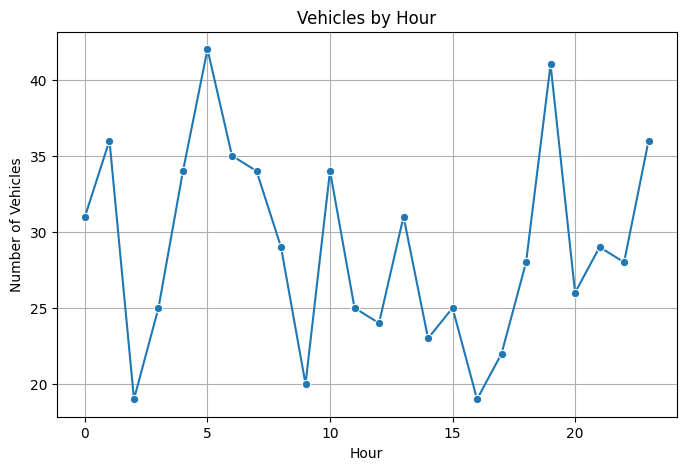

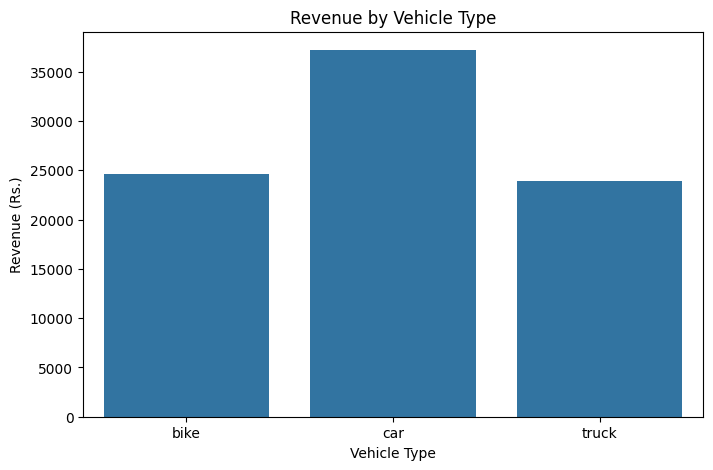

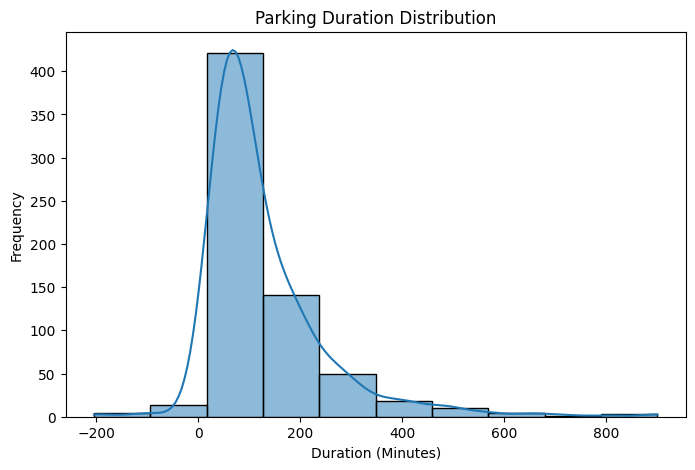

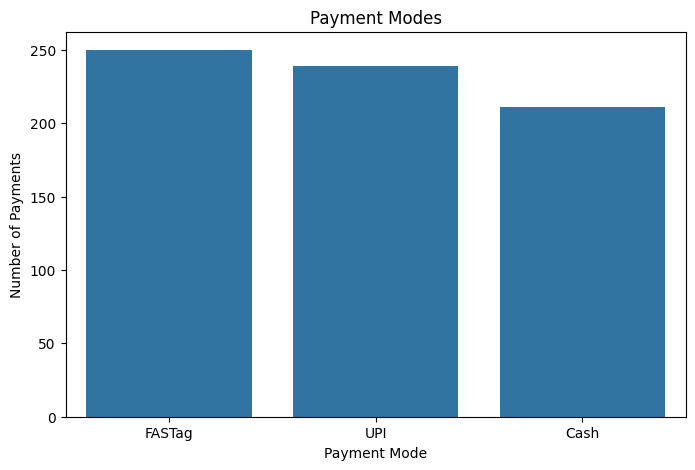

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_dataset.csv")

df["entry_time"] = pd.to_datetime(df["entry_time"])
df["exit_time"] = pd.to_datetime(df["exit_time"])

df["duration_min"] = (
    df["exit_time"] - df["entry_time"]
).dt.total_seconds() / 60

# Chart 1: Line Chart - Vehicles by Hour

df["hour"] = df["entry_time"].dt.hour

hour_count = df["hour"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.lineplot(x=hour_count.index, y=hour_count.values, marker="o")

plt.title("Vehicles by Hour")
plt.xlabel("Hour")
plt.ylabel("Number of Vehicles")
plt.grid()
plt.show()


# Chart 2: Bar Chart - Revenue by Vehicle Type

revenue = df.groupby("vehicle_type")["fee_charged"].sum()

plt.figure(figsize=(8, 5))
sns.barplot(x=revenue.index, y=revenue.values)

plt.title("Revenue by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Revenue (Rs.)")
plt.show()


# Chart 3: Histogram - Parking Duration

plt.figure(figsize=(8, 5))
sns.histplot(df["duration_min"].dropna(), bins=10, kde=True)

plt.title("Parking Duration Distribution")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Frequency")
plt.show()


# Chart 4: Bar Chart - Payment Modes

payment_count = df["payment_mode"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=payment_count.index, y=payment_count.values)

plt.title("Payment Modes")
plt.xlabel("Payment Mode")
plt.ylabel("Number of Payments")
plt.show()

In [37]:
codes = [72, 105]

answer = ""

for num in codes:
    answer = answer + chr(num)

print(answer)

Hi
